In [1]:
import copy
import random

import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from lab8.models import WeatherLSTM


plt.rcParams.update({
    "figure.figsize": (12, 4),
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 16,
    "font.family": "Times New Roman",
})

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

# 1. Подготовка данных

In [2]:
SEED = 42
BATCH_SIZE = 32
HIDDEN_SIZE = 16
LEARNING_RATE = 0.001
WEIGHT_DECAY = 0.001
MAX_EPOCHS = 150
PATIENCE = 15

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
print("Устройство:", device)

Устройство: cuda


In [3]:
required_files = ["prepared.npz", "preprocessing.json", "observations.csv"]

for name in required_files:
    if not (ARTIFACTS_DIR / name).is_file():
        raise FileNotFoundError(f"Нет файла {name}!")
    
meta = json.loads((ARTIFACTS_DIR / 'preprocessing.json').read_text(encoding='utf-8'))

with np.load(ARTIFACTS_DIR / 'prepared.npz', allow_pickle=False) as data:
    X_train, y_train = data['X_train'].copy(), data['y_train'].copy()
    X_val, y_val = data['X_val'].copy(), data['y_val'].copy()
    val_dates = pd.to_datetime(data['dates_val'])

data_hashes = {
    name: hashlib.sha256((ARTIFACTS_DIR / name).read_bytes()).hexdigest()
    for name in ["prepared.npz", "preprocessing.json", "observations.csv"]
}
    
print( "Train:", X_train.shape )
print( "Validation:", X_val.shape )

Train: (701, 30, 6)
Validation: (365, 30, 6)


Порядок дней внутри окна сохраняется. Перемешиваются только обучающие окна.


In [4]:
train_x = torch.from_numpy(X_train)
train_y = torch.from_numpy(y_train)
train_dataset = TensorDataset(train_x, train_y)

generator = torch.Generator().manual_seed(SEED)

loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0,
)

val_x = torch.from_numpy(X_val).to(device)
val_y = torch.from_numpy(y_val).to(device)

print('PyTorch:', torch.__version__, '| Устройство:', device)

PyTorch: 2.14.1+cu130 | Устройство: cuda


## 2. Модель

Однослойная LSTM → линейный одномерный слой → температура следующего дня.

Вход: `(batch, 30, 6)`. Выход: `(batch)`

In [ ]:
config = {
    "input_size": X_train.shape[2],
    "hidden_size": HIDDEN_SIZE,
    "num_layers": 1,
    "head_type": "linear",
}
model = WeatherLSTM(**config).to(device)
print(model)

WeatherLSTM(
  (lstm): LSTM(6, 16, batch_first=True)
  (head): Sequential(
    (0): Linear(in_features=16, out_features=1, bias=True)
  )
)


## 3. Обучение

MSE и AdamW. Лучшая эпоха выбирается по validation MSE.
Остановка после 15 эпох без улучшения.
Train и validation на графике оцениваются в режиме eval.

Эпоха   1 | train MSE: 0.6784 | val MSE: 0.6947 | val MAE: 4.88 °C | lr: 0.001000
Эпоха  10 | train MSE: 0.1738 | val MSE: 0.2021 | val MAE: 2.56 °C | lr: 0.001000
Эпоха  20 | train MSE: 0.1523 | val MSE: 0.1764 | val MAE: 2.42 °C | lr: 0.001000
Эпоха  30 | train MSE: 0.1380 | val MSE: 0.1594 | val MAE: 2.31 °C | lr: 0.001000
Эпоха  40 | train MSE: 0.1265 | val MSE: 0.1484 | val MAE: 2.23 °C | lr: 0.001000
Эпоха  50 | train MSE: 0.1176 | val MSE: 0.1395 | val MAE: 2.17 °C | lr: 0.001000
Эпоха  60 | train MSE: 0.1112 | val MSE: 0.1372 | val MAE: 2.16 °C | lr: 0.001000
Эпоха  70 | train MSE: 0.1072 | val MSE: 0.1367 | val MAE: 2.16 °C | lr: 0.000500
Эпоха  80 | train MSE: 0.1047 | val MSE: 0.1368 | val MAE: 2.16 °C | lr: 0.000250
Ранняя остановка.


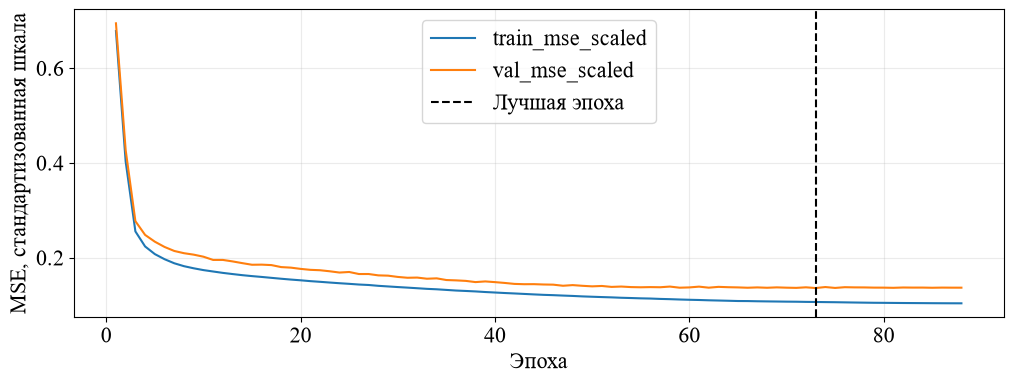

Лучшая эпоха: 73


In [ ]:
# Каждый запуск начинает обучение с новых весов.
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if device.type == "cuda":
    torch.cuda.manual_seed_all(SEED)

model = WeatherLSTM(**config).to(device)

loader = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED), 
    num_workers=0,
)

optimizer = torch.optim.AdamW(
    model.parameters(), 
    lr=LEARNING_RATE, 
    weight_decay=WEIGHT_DECAY,
)

loss_fn = nn.MSELoss()

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode="min", 
    factor=0.5, 
    patience=5, 
    min_lr=1e-5,
)

best_loss = float("inf")
best_epoch = 0
best_state = None
epochs_without_improvement = 0
history = []
train_eval_x = train_x.to(device)
train_eval_y = train_y.to(device)

for epoch in range(1, MAX_EPOCHS + 1):
    
    model.train()
    train_loss_sum = 0.0
    
    for batch_x, batch_y in loader:
        
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        
        optimizer.zero_grad(set_to_none=True)
        
        loss = loss_fn(model(batch_x), batch_y)
        
        if not torch.isfinite(loss).item():
            raise RuntimeError("Некорректная ошибка обучения.")
        
        loss.backward()
        
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        train_loss_sum += loss.item() * len(batch_x)

    # Обе кривые считаем с одинаковыми весами в режиме eval.
    model.eval()
    with torch.no_grad():
        train_loss = loss_fn(model(train_eval_x), train_eval_y).item()
        val_prediction = model(val_x)
        val_loss = loss_fn(val_prediction, val_y).item()
        val_mae = (val_prediction - val_y).abs().mean().item() * meta["y_std"]

    if not np.isfinite(val_loss):
        raise RuntimeError("Некорректная ошибка валидации.")
    learning_rate = optimizer.param_groups[0]["lr"]
    history.append({
        "epoch": epoch,
        "train_mse_scaled": train_loss,
        "train_batch_mse_scaled": train_loss_sum / len(train_dataset),
        "val_mse_scaled": val_loss,
        "val_mae_C": val_mae,
        "learning_rate": learning_rate,
    })
    scheduler.step(val_loss)
    if val_loss < best_loss:
        best_loss = val_loss
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f"Эпоха {epoch:3d} | train MSE: {train_loss:.4f} | "
              f"val MSE: {val_loss:.4f} | val MAE: {val_mae:.2f} °C | lr: {learning_rate:.6f}")
    if epochs_without_improvement >= PATIENCE:
        print("Ранняя остановка.")
        break

if best_state is None:
    raise RuntimeError("Лучшие веса не получены.")

model.load_state_dict(best_state, strict=True)
model.eval()

history = pd.DataFrame(history)
history.plot(x="epoch", y=["train_mse_scaled", "val_mse_scaled"])

plt.axvline(best_epoch, color="black", linestyle="--", label="Лучшая эпоха")
plt.xlabel("Эпоха")
plt.ylabel("MSE, стандартизованная шкала")
plt.legend()
plt.show()
print("Лучшая эпоха:", best_epoch)

## 4. Сравнение на validation

- `persistence` — температура предыдущего дня. 
- `mean_7` — среднее прошлых семи дней.
- `seasonal` — годовая синусоида, подобранная на train.
- Модель выбирается по минимальному RMSE на validation.

In [7]:
observations = pd.read_csv(ARTIFACTS_DIR / 'observations.csv', parse_dates=['date']).set_index('date')

# Коэффициенты сезонного прогноза оцениваем на train.
def seasonal_design(index):
    angle = 2 * np.pi * (index.dayofyear - 1) / np.where(index.is_leap_year, 366, 365)
    return np.column_stack([np.ones(len(index)), np.sin(angle), np.cos(angle)])

train_obs = observations.loc[observations.index < pd.Timestamp(meta['train_end_exclusive'])]

coef = np.linalg.lstsq(seasonal_design(train_obs.index), train_obs.temp_max.to_numpy(), rcond=None)[0]

model.eval()

with torch.no_grad():
    
    pred = model(val_x).cpu().numpy() * meta['y_std'] + meta['y_mean']
truth = y_val * meta['y_std'] + meta['y_mean']

val_predictions = pd.DataFrame({
    'actual': truth, 'lstm': pred,
    'persistence': observations.temp_max.shift(1).reindex(val_dates).to_numpy(),
    'mean_7': observations.temp_max.shift(1).rolling(7).mean().reindex(val_dates).to_numpy(),
    'seasonal': seasonal_design(val_dates) @ coef}, index=val_dates)

val_scores = pd.DataFrame({name: {
    'MAE_C': np.mean(np.abs(val_predictions[name] - truth)),
    'RMSE_C': np.sqrt(np.mean((val_predictions[name] - truth)**2))
} for name in ['lstm', 'persistence', 'mean_7', 'seasonal']}).T.sort_values('RMSE_C')

display(val_scores.round(3))
selected = str(val_scores.index[0])

,MAE_C,RMSE_C
lstm,2.154,2.701
persistence,2.276,2.955
mean_7,2.894,3.683
seasonal,2.986,3.821


## 5. Сохранение результатов

- `lstm.pt` — лучшие веса и конфигурация;
- `training_history.csv` — история обучения;
- `validation_predictions.csv` и `validation_metrics.csv` — результаты на validation;
- `seasonal_coef.npy` — коэффициенты сезонного прогноза;
- `selection.json` — выбор модели и настройки.

Повторный запуск заменяет эти файлы.

In [8]:
torch.save({'state_dict': best_state, 'architecture': 'direct_lstm_no_dropout_v3', 'data_hashes': data_hashes, 'config': config, 'best_epoch': best_epoch,
            'raw_sha256': meta['raw_sha256'], 'features': meta['features'],
            'lookback': meta['lookback'], 'y_mean': meta['y_mean'], 'y_std': meta['y_std']},
           ARTIFACTS_DIR / 'lstm.pt')
np.save(ARTIFACTS_DIR / 'seasonal_coef.npy', coef)
val_predictions.to_csv(ARTIFACTS_DIR / 'validation_predictions.csv', index_label='date')
val_scores.to_csv(ARTIFACTS_DIR / 'validation_metrics.csv', index_label='model')
(ARTIFACTS_DIR / 'selection.json').write_text(json.dumps({
    'selected_by_validation_rmse': selected, 'data_hashes': data_hashes, 'seed': SEED,
    'best_epoch': best_epoch, 'torch_version': str(torch.__version__),
    'numpy_version': np.__version__, 'pandas_version': pd.__version__,
    'config': config, 'learning_rate': LEARNING_RATE, 'weight_decay': WEIGHT_DECAY,
    'max_epochs': MAX_EPOCHS, 'patience': PATIENCE,
}, indent=2), encoding='utf-8')

history.to_csv(ARTIFACTS_DIR / "training_history.csv", index=False)
